# Transfer Learning and Fine-Tuning of Pretrained Models

This notebook investigates the use of transfer learning for classifying knee osteoarthritis  severity from X-ray images.

Two pretrained convolutional neural network (CNN) architectures are investigated:
- **ResNet18:** A residual neural network that uses skip connections to facilitate training and improve gradient propagation.
- **EfficientNet-B0:** A computationally efficient CNN architecture that balances network depth, width, and input resolution.

Both models are initialized with weights pretrained on ImageNet. Instead of training all parameters from scratch, transfer learning allows the models to reuse previously learned visual features and adapt them to the knee X-ray classification task.

The models are trained using a two-stage approach:

1. **Feature extraction:** The pretrained backbone is frozen, and only the newly initialized classification head is trained.

2. **Fine-tuning:** Selected deeper layers are unfrozen and trained using smaller learning rates to adapt the learned features to the medical imaging dataset.

Since the dataset contains a considerable imbalance between KL grades, different augmentation and sampling strategies are also considered.

The objective is to investigate how effectively pretrained CNN architectures can distinguish between different stages of knee osteoarthritis and how fine-tuning affects their classification performance.

## Import everything in colab

The follwing cell sets up the project in a fresh Colab runtime. This clones the repository, loads the dependencies and configures settings.

In [1]:
!git clone https://github.com/michael-duer/medical-image-classification.git
%cd medical-image-classification

Cloning into 'medical-image-classification'...
remote: Enumerating objects: 8391, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 8391 (delta 2), reused 27 (delta 1), pack-reused 8361 (from 2)
Receiving objects: 100% (8391/8391), 310.64 MiB | 19.35 MiB/s, done.
Resolving deltas: 100% (35/35), done.
Updating files: 100% (8303/8303), done.
/content/medical-image-classification


In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
import timm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Set paths
DATA_DIR = Path('/content/medical-image-classification/data')
OUTPUT_DIR = Path('/content/medical-image-classification/output')

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Set DATA_DIR to your actual dataset folder first: {DATA_DIR}")
print('Dataset path:', DATA_DIR.resolve())

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Dataset path: /content/medical-image-classification/data


## 1. Data Loading and Preprocessing

The data is already split into `train`, `test` and `eval` folders. The same label mapping and normalization will be used by every model.

The training set contains 5'778 images. However, the distribution across the five classes is highly imbalanced, with KL grade 0 being the most frequent and KL grade 4 being the least frequent.

This imbalance can influence model training, as the network may become biased toward frequently occurring classes while performing poorly on underrepresented severity grades.

To investigate this problem, different preprocessing approaches were considered:

1. **Baseline preprocessing:** Images are resized and normalized without additional augmentation or class balancing.

2. **Balanced augmentation:** Minority classes are oversampled using small random image rotations until all classes contain the same number of training entries.

3. **Random augmentation with weighted sampling:** Mild transformations are applied to the training images, while a weighted sampling strategy is used to increase the frequency of underrepresented classes during training.

The final approach was selected based on validation performance.

Random augmentation is applied only to the training dataset. Validation and test images undergo deterministic preprocessing to ensure consistent evaluation.

In [3]:
from torchvision.datasets.folder import default_loader
from src.class_imbalance import (
    get_transforms,
    create_weighted_sampler
)

# Normalization matches common ImageNet-pretrained ResNet/EfficientNet weights.
# Keep these choices the same in all experiments.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

IMAGE_SIZE = 224
BATCH_SIZE = 16

class ImageSubset(Dataset):
    """ImageFolder-compatible subset that stores explicit (path, label) entries."""
    def __init__(self, samples, transform):
        self.samples = [(str(p), int(y)) for p, y in samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = default_loader(path)  # RGB
        return self.transform(img), label


### 1.1 Baseline preprocessing

In [ ]:
# Load datasets
train_source = datasets.ImageFolder(DATA_DIR / 'train')
val_source = datasets.ImageFolder(DATA_DIR / 'val')
test_source = datasets.ImageFolder(DATA_DIR / 'test')

split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }

base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

datasets_by_split = {
    split: ImageSubset(samples, base_transform)
    for split, samples in split_samples.items()
}
loaders = {
    split: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == 'train'),
                      pin_memory=(DEVICE.type == 'cuda'))
    for split, ds in datasets_by_split.items()
}

class_names = train_source.classes
num_classes = len(class_names)

### 1.2 Balanced augmentation
One approach to addressing class imbalance is to increase the number of training examples belonging to underrepresented classes.

In this experiment, a custom BalancedAugmentedDataset is used to balance the class distribution. All original training images are retained, while additional entries are created for minority classes until every class contains the same number of samples.

These additional entries reuse existing images and apply random rotations of up to ±5 degrees when loaded. Reflection padding is applied before rotation to reduce the appearance of empty borders.

The use of relatively small rotations is intentional because knee X-rays contain subtle anatomical characteristics that are important for determining osteoarthritis severity.

Although oversampling produces a balanced training distribution, it does not increase the number of independent patient images. Repeated exposure to variations of the same images may therefore increase the risk of overfitting, particularly for the smallest class (KL grade 4).

In [ ]:
from src.data_augmentation import BalancedAugmentedDataset

# Apply augmentation to training data to handle class imbalance
train_dataset = BalancedAugmentedDataset(
    split_samples["train"],
    image_size=IMAGE_SIZE,
    max_rotation=5,
    seed=SEED,
    mean=MEAN,
    std=STD
)

# Validation and test transformations (no augmentation)
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Validation and test datasets: unchanged
val_dataset = ImageSubset(
    split_samples["val"],
    base_transform
)

test_dataset = ImageSubset(
    split_samples["test"],
    base_transform
)

datasets_by_split = {
    "train": train_dataset,
    "val": val_dataset,
    "test": test_dataset
}

loaders = {
    split: DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=(split == "train"),
        pin_memory=(DEVICE.type == "cuda")
    )
    for split, ds in datasets_by_split.items()
}

images, labels = next(iter(loaders["train"]))
print("One batch:", images.shape)

### 1.3 Random augmentation with weighted sampling
As an alternative to explicitly creating a balanced dataset, weighted random sampling is used to account for differences in class frequencies.

A `WeightedRandomSampler` assigns individual training images a sampling probability based on the frequency of their class. Images belonging to less frequent classes receive higher sampling weights and are therefore more likely to be selected during training.

The class weights are calculated as:

$w_c = \frac{1}{n_c^\alpha}$

where $n_c$ represents the number of training images in class $c$, and $\alpha$ determines the strength of the balancing.

In the current configuration, $\alpha = 1$, corresponding to inverse-frequency weighting. This results in approximately equal expected sampling probabilities across the five KL grades.

Unlike the previous approach, weighted sampling does not explicitly expand the dataset to the size of the largest class. Instead, a fixed number of samples is drawn with replacement during each epoch.

Additionally, mild random augmentations are applied to the training images:

- Random rotations of up to ±5 degrees
- Random horizontal flipping
- Small brightness and contrast adjustments

These transformations introduce variations in the training data and may help improve generalization. The transformations are deliberately limited to reduce the risk of altering clinically relevant anatomical features.

Validation and test images are not randomly augmented.

The weighted sampling approach allows class imbalance to be addressed independently of the image augmentation process.

In [4]:

from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision.datasets.folder import default_loader
from torchvision import transforms

NUM_CLASSES = 5

# Load datasets
train_source = datasets.ImageFolder(DATA_DIR / 'train')
val_source = datasets.ImageFolder(DATA_DIR / 'val')
test_source = datasets.ImageFolder(DATA_DIR / 'test')

split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }

# Mild augmentation for knee X-rays
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# No random augmentation for validation/test
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_dataset = ImageSubset(
    split_samples["train"],
    train_transform
)

val_dataset = ImageSubset(
    split_samples["val"],
    base_transform
)

test_dataset = ImageSubset(
    split_samples["test"],
    base_transform
)

# Build weighted sampler from original training labels
labels = np.array([
    label for _, label in split_samples["train"]
])

counts = np.bincount(labels, minlength=NUM_CLASSES)

# Softer balancing than 1/count
alpha = 1
class_weights = 1.0 / (counts ** alpha)
sample_weights = class_weights[labels]

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double
    ),
    num_samples=len(labels),
    replacement=True
)

datasets_by_split = {
    "train": train_dataset,
    "val": val_dataset,
    "test": test_dataset
}

loaders = {
    "train": DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        sampler=sampler,
        pin_memory=(DEVICE.type == "cuda")
    ),
    "val": DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    ),
    "test": DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        pin_memory=(DEVICE.type == "cuda")
    )
}

print("Original class counts:", counts)
print("Class sampling weights:", class_weights)
print("Training batches:", len(loaders["train"]))


Original class counts: [2286 1046 1516  757  173]
Class sampling weights: [0.00043745 0.00095602 0.00065963 0.001321   0.00578035]
Training batches: 362


## 2. Transfer learning & Fine Tuning


### 2.1 Set Training parameters
Specify learning rate, loss function and number of training loops (epochs). Also specify the number of classes to predict as we will replace the last layer of the following models with a classifier suitable for our task.

In [5]:
NUM_CLASSES = 5
NUM_EPOCHS_STAGE1 = 8
NUM_EPOCHS_STAGE2 = 20
criterion = nn.CrossEntropyLoss()

A shared training function is used for both pretrained architectures to ensure a consistent training and validation procedure.

During each training epoch, the model processes the training images in batches, calculates the cross-entropy loss, and updates the trainable parameters using backpropagation.

In [6]:
def run_epoch(model, loader, optimizer=None, epoch=None, num_epochs=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, correct, count = 0.0, 0, 0

    phase = "Train" if is_training else "Validate"
    description = f"Epoch [{epoch}/{num_epochs}] | {phase}"

    with tqdm(loader, leave=False, desc=description) as progressbar:
      for x, y in progressbar:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(x)
            loss = criterion(logits, y)

            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)

        progressbar.set_postfix(
            loss=f"{total_loss / count:.4f}",
            acc=f"{correct / count:.2%}"
        )

    return {'loss': total_loss / count, 'accuracy': correct / count}

### 2.2 Transfer Learning with ResNet18
ResNet18 is a convolutional neural network consisting of 18 weighted layers. Its architecture uses residual connections that allow information to bypass certain layers, helping to reduce difficulties associated with training deep neural networks.

For this experiment, ResNet18 is initialized with pretrained ImageNet weights using the `timm` library.

The original classification layer is replaced with a new fully connected layer containing five output neurons, corresponding to the five KL grades.

Instead of immediately updating the entire network, training is divided into two stages.

**Stage 1: Training the classification head**

Initially, all pretrained layers are frozen by setting `requires_grad = False`. Only the new classification layer (`fc`) remains trainable.

This allows the network to learn how to map its existing visual features to the five osteoarthritis severity grades without modifying the pretrained feature extractor.

Since the new classification layer is randomly initialized, a relatively higher learning rate is used to allow it to adapt quickly to the classification task.

In [8]:
# Create pretrained ResNet18 with 5 output classes
resnet18 = timm.create_model(
    'resnet18',
    pretrained=True,
    num_classes=NUM_CLASSES
    )

# Freeze pretrained backbone
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

# Move the model to gpu
resnet18 = resnet18.to(DEVICE)

# Only optimize classifier parameters
optimizer = torch.optim.AdamW(
    resnet18.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

#### 2.2.1 Training the Classification Head
The model is trained for a maximum of 8 epochs in the first stage.

To reduce the risk of overfitting, early stopping is applied based on the validation loss. Whenever the validation loss improves, the model weights are saved as a checkpoint.

If the validation loss does not improve for four consecutive epochs, training is stopped.

Additionally, the `ReduceLROnPlateau` learning rate scheduler is used. If the validation loss stagnates, the scheduler reduces the learning rate by a factor of 0.5.

This allows the optimizer to make smaller parameter updates when training progress slows.

The checkpoint with the lowest validation loss is retained for the subsequent fine-tuning stage, rather than automatically using the weights from the final epoch.

Epoch [1/8] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [1/8] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [1/8] | Train Loss: 1.5707 | Train Acc: 28.25% | Val Loss: 1.4960 | Val Acc: 32.20%


Epoch [2/8] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [2/8] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

...

Epoch [7/8] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [7/8] | Train Loss: 1.3775 | Train Acc: 39.36% | Val Loss: 1.3292 | Val Acc: 40.68%


Epoch [8/8] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [8/8] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [8/8] | Train Loss: 1.3507 | Train Acc: 41.12% | Val Loss: 1.3571 | Val Acc: 35.11%


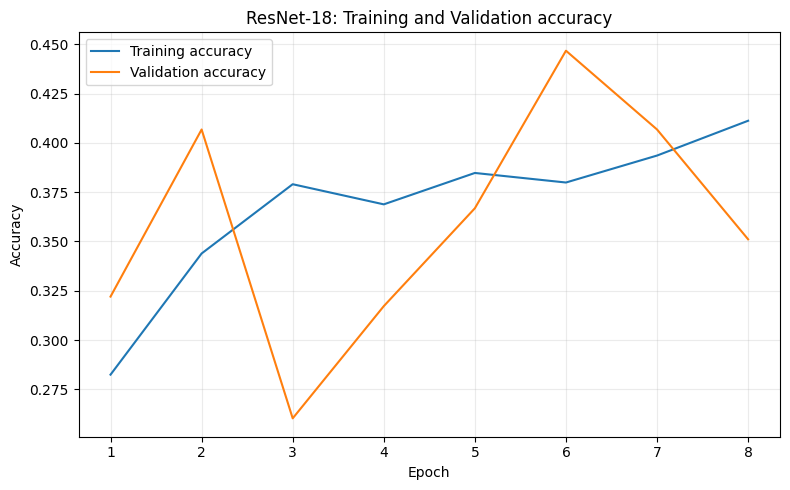

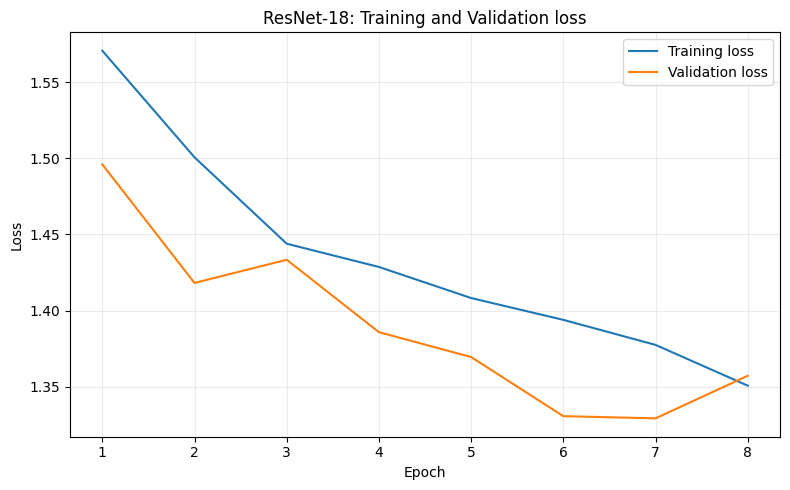

{}

In [ ]:
history_resnet18 = []
best_val_loss = float("inf")
# Stops model after 4 epochs of not improving validation loss
early_stop_rate = 4
epochs_without_improvement = 0
# Reduce learning rates when validation loss stagnates
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

for epoch in range(1, NUM_EPOCHS_STAGE1 + 1):
    train_stats = run_epoch(
        resnet18, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE1
    )

    val_stats = run_epoch(
        resnet18, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE1
    )

    history_resnet18.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS_STAGE1}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

    scheduler.step(val_stats['loss'])

    # Stop training if validation loss does not improve
    if val_stats['loss'] < best_val_loss:
        best_val_loss = val_stats['loss']
        epochs_without_improvement = 0
        # Save best model
        torch.save(resnet18.state_dict(), "best_resnet18_stage1.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_rate:
        print("Early stopping triggered!")
        break

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_resnet18,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="ResNet-18",
    show_plots = True,
    save_plots = False
)

**Stage 1 Observations**

During the initial training stage, the training loss decreases from approximately 1.57 to 1.35 in the later epochs, while training accuracy reaches approximately 41%.

Validation accuracy fluctuates considerably and reaches its highest value of approximately 44.7% in epoch 6. The lowest validation loss is obtained in epoch 7.

Although the classification head learns to use the pretrained features, the relatively low accuracy suggests that these features alone are not sufficient for reliable differentiation between the five KL grades.

Therefore, additional fine-tuning is performed to adapt the higher-level features of ResNet18 to the specific characteristics of knee X-rays.

#### 2.2.2 Fine-Tuning the Last Residual Block
After training the classification head, the best-performing Stage 1 checkpoint is restored.

The fine-tuning stage is performed for a maximum of 20 epochs. Here the final residual block (`layer4`) is unfrozen in addition to the classification head. All earlier layers remain frozen.

This approach allows the network to adapt its deeper visual features to knee X-ray images while preserving more general features learned during ImageNet pretraining.

The final residual block (`layer4`) and classification head (`fc`) are trained using separate learning rates of `1e-4` and `1e-3`, respectively.

The smaller learning rate for the residual block is intended to preserve useful pretrained representations while allowing them to adapt to the knee X-ray dataset. The classifier receives a larger learning rate to adjust its predictions to the updated features.

Early stopping is again applied based on validation loss, and the best-performing checkpoint is saved separately.

This gradual fine-tuning strategy aims to improve model generalization while reducing the risk of overfitting.

In [44]:
# Restore best model from Stage 1
resnet18.load_state_dict(
    torch.load(
        "best_resnet18_stage1.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

# Freeze all layers
for param in resnet18.parameters():
    param.requires_grad = False

# Unfreeze layer4 (layer before classifier)
for param in resnet18.layer4.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in resnet18.fc.parameters():
    param.requires_grad = True

# Set optimizer with different learning rates
optimizer = torch.optim.AdamW(
    [
        {
            "params": resnet18.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": resnet18.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)

# New scheduler for Stage 2
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

Train again

Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.2663 | Train Acc: 43.68% | Val Loss: 1.2135 | Val Acc: 47.58%


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [2/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

...

Epoch [18/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [18/20] | Train Loss: 0.7514 | Train Acc: 67.27% | Val Loss: 1.1066 | Val Acc: 50.48%


Epoch [19/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [19/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [19/20] | Train Loss: 0.7324 | Train Acc: 68.09% | Val Loss: 1.0992 | Val Acc: 50.48%
Early stopping triggered!


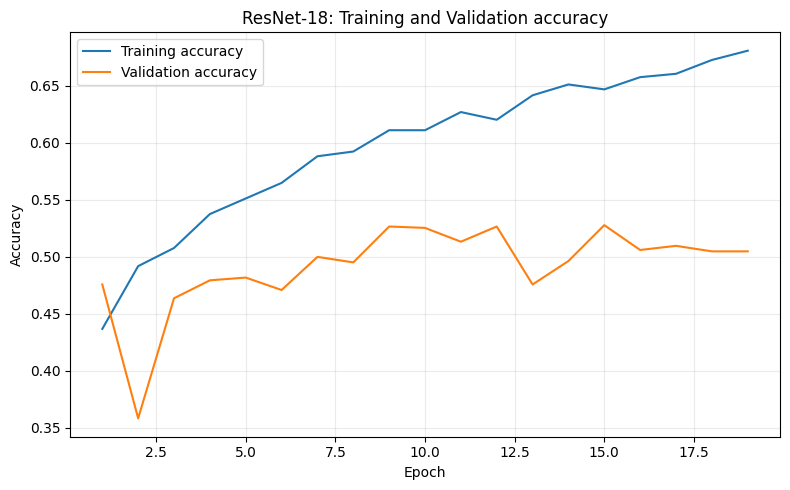

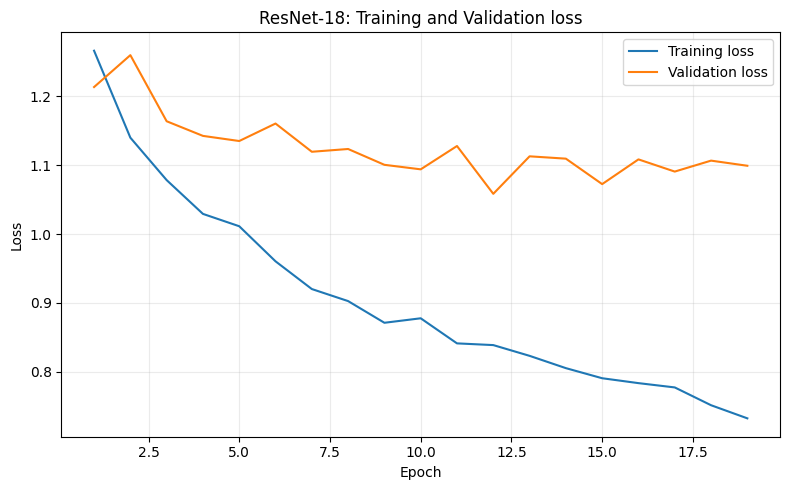

{}

In [45]:
history_resnet18 = []
best_val_loss = float("inf")
# Stops model after 4 epochs of not improving validation loss
early_stop_rate = 7
epochs_without_improvement = 0
# Reduce learning rates when validation loss stagnates
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

for epoch in range(1, NUM_EPOCHS_STAGE2 + 1):
    train_stats = run_epoch(
        resnet18, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE2
    )

    val_stats = run_epoch(
        resnet18, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE2
    )

    history_resnet18.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS_STAGE2}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

    scheduler.step(val_stats['loss'])

    # Stop training if validation loss does not improve
    if val_stats['loss'] < best_val_loss:
        best_val_loss = val_stats['loss']
        epochs_without_improvement = 0
        # Save best model
        torch.save(resnet18.state_dict(), "best_resnet18_stage2.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_rate:
        print("Early stopping triggered!")
        break

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_resnet18,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="ResNet-18",
    show_plots = True,
    save_plots = False
)

#### 2.2.3 Evaluation of ResNet18
After training, the model is evaluated using the validation dataset.

Two primary metrics are calculated:

- **Accuracy** measures the percentage of images for which the predicted KL grade exactly matches the ground-truth label.
- **Area Under the Receiver Operating Characteristic Curve (AUROC)** measures the model's ability to distinguish between classes across different classification thresholds.

Since this is a five-class classification problem, AUROC is calculated using a one-vs-rest approach with macro averaging. Each class is evaluated against all remaining classes, and the five AUROC scores are averaged with equal weight.

A confusion matrix is also generated to examine how frequently the model confuses different KL grades.

In [48]:
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    actual, probs = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        actual.append(y.numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(actual), np.concatenate(probs)

def summarize_metrics(y_true, probabilities, class_names):
    predictions = probabilities.argmax(axis=1)
    results = {'accuracy': accuracy_score(y_true, predictions)}
    present = np.unique(y_true)
    if len(class_names) == 2 and len(present) == 2:
        results['auroc'] = roc_auc_score(y_true, probabilities[:, 1])
    elif len(present) == len(class_names):
        results['auroc'] = roc_auc_score(
            y_true, probabilities, labels=np.arange(len(class_names)),
            multi_class='ovr', average='macro')
    else:
        results['auroc'] = float('nan')
        print('AUROC undefined: not all classes appear in this validation split.')
    return results, confusion_matrix(y_true, predictions,
                                      labels=np.arange(len(class_names)))

# Load best model
resnet18.load_state_dict(
    torch.load(
        # Newly trained models appear in the root folder
        #"best_resnet18_stage2.pth",
        # While the best models are in folder /models
        "./models/best_resnet18_stage2.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

y_val, val_prob = get_predictions(resnet18, loaders['val'])
class_names = train_source.classes
metrics, cm = summarize_metrics(y_val, val_prob, class_names)
print('Validation metrics:', metrics)
print('Confusion matrix (rows=true, cols=predicted):')
display(pd.DataFrame(cm, index=class_names, columns=class_names))

Validation metrics: {'accuracy': 0.5266343825665859, 'auroc': np.float64(0.8095281737838487)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,229,45,42,11,1
1,97,18,29,7,2
2,57,31,93,29,2
3,4,4,25,69,4
4,0,0,0,1,26


Current backend: module://matplotlib_inline.backend_inline
True labels: (1656,)
Predicted probabilities: (1656, 5)


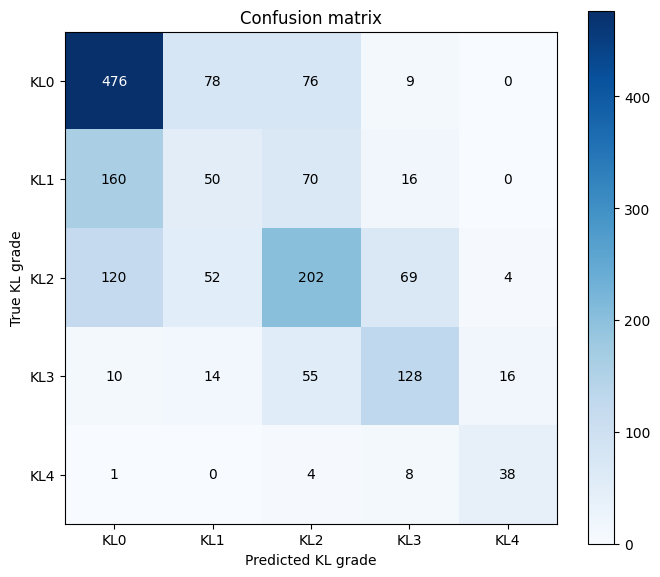

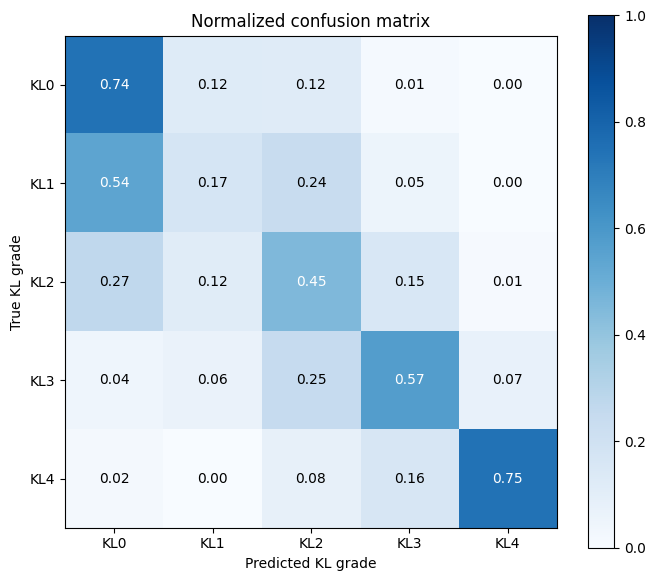

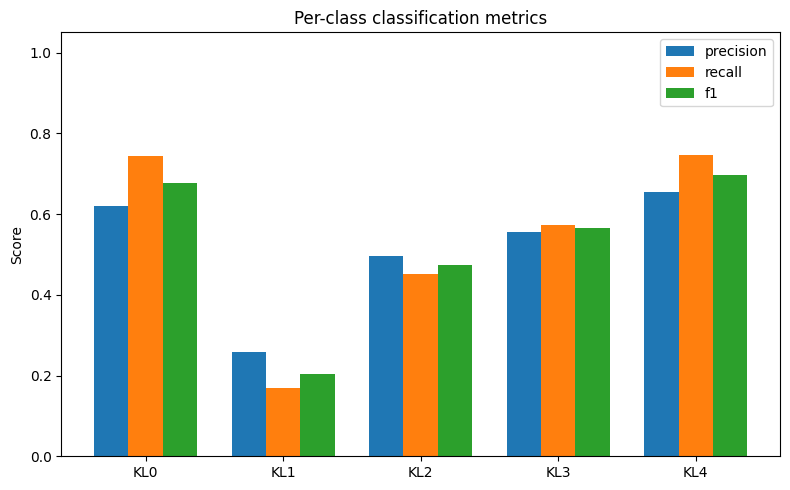

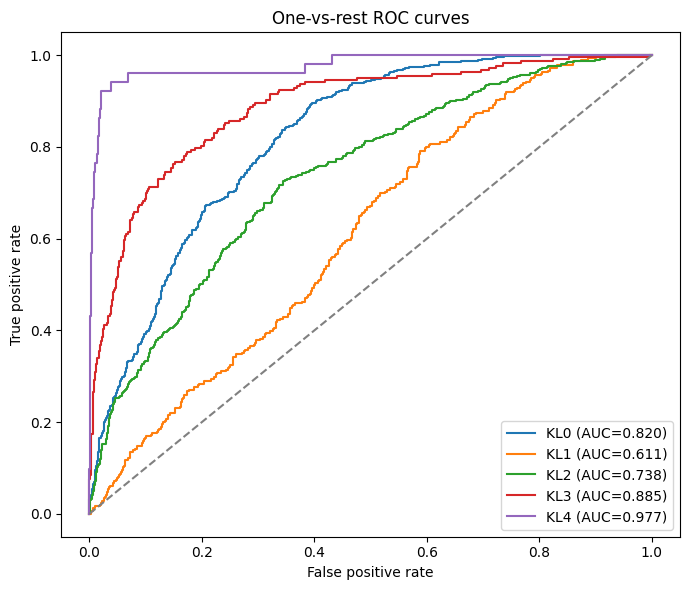

{'model_name': 'ResNet-18', 'n_samples': 1656, 'accuracy': 0.5398550724637681, 'balanced_accuracy': 0.536964696706557, 'macro_f1': 0.5233233636703678, 'weighted_f1': 0.5230174806834318, 'quadratic_weighted_kappa': 0.6683824587475684, 'mae': 0.626207729468599, 'macro_auroc_ovr': 0.8064139646301014}


In [49]:
import matplotlib
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")

print("Current backend:", matplotlib.get_backend())

# Generate predictions
y_test, test_prob = get_predictions(resnet18, loaders["test"])

print("True labels:", y_test.shape)
print("Predicted probabilities:", test_prob.shape)

from src.metrics import evaluate_predictions

# Evaluate CNN performance
results = evaluate_predictions(
    y_true=y_test,
    y_prob=test_prob,
    model_name="ResNet-18",
    show_plots=True,
    save_plots=False
)

print(results)

**ResNet18 Results**

The fine-tuned ResNet18 model achieves a validation accuracy of approximately **52.7%** and a macro-averaged AUROC of **0.810**.

The evaluation on the test dataset produces an accuracy of approximately **54%**, a macro F1-score of **0.52**, and a quadratic weighted kappa of **0.67**.

The test AUROC of **0.806** indicates that the model has learned useful features for distinguishing between different osteoarthritis severity grades.

However, the exact classification accuracy remains relatively limited, with approximately half of the X-rays assigned to an incorrect KL grade.

Since the KL grades represent an ordered classification problem, quadratic weighted kappa provides additional information by considering the magnitude of classification errors. The obtained value suggests meaningful agreement between the predicted and actual grades beyond chance.

The results indicate that ResNet18 is able to capture relevant radiographic patterns, but still has difficulty assigning the correct grade consistently.

The relatively similar validation and test AUROC values are encouraging, although they do not establish generalization to independent clinical populations.

### 2.3 Fine Tune EfficientNet-B0
EfficientNet-B0 is a convolutional neural network designed to achieve high classification performance while using computational resources efficiently.

Unlike ResNet18, which uses residual blocks, EfficientNet-B0 uses mobile inverted bottleneck convolution blocks and squeeze-and-excitation mechanisms to extract visual features. [Efficientnet Architecture explained](https://www.geeksforgeeks.org/computer-vision/efficientnet-architecture/)

As with ResNet18, the model is initialized using ImageNet-pretrained weights from the `timm` library. The original classification head is replaced with a new layer containing five output neurons corresponding to the Kellgren-Lawrence grades.

To enable a comparable training procedure, EfficientNet-B0 is trained using the same two-stage transfer learning strategy.

During the first stage, all pretrained layers are frozen, and only the newly initialized `classifier` layer is trained.

This allows the model to learn how to classify the five KL grades using the features already extracted by the pretrained backbone.

In [23]:
# Create pretrained EfficientNet-B0 with 5 output classes
efficientnet_b0 = timm.create_model(
    'efficientnet_b0',
    pretrained=True,
    num_classes=NUM_CLASSES
    )

# Freeze pretrained backbone
for param in efficientnet_b0.parameters():
    param.requires_grad = False

# Unfreeze classification head
for param in efficientnet_b0.classifier.parameters():
    param.requires_grad = True

# Move the model to gpu
efficientnet_b0 = efficientnet_b0.to(DEVICE)

# Only optimize classifier parameters
optimizer = torch.optim.AdamW(
    efficientnet_b0.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

#### 2.3.1 Training the Classification Head

Epoch [1/8] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/8] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/8] | Train Loss: 2.5922 | Train Acc: 24.90% | Val Loss: 2.3152 | Val Acc: 27.60%


Epoch [2/8] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [2/8] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

...

Epoch [7/8] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [7/8] | Train Loss: 1.5802 | Train Acc: 39.27% | Val Loss: 1.5582 | Val Acc: 36.08%


Epoch [8/8] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [8/8] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [8/8] | Train Loss: 1.5237 | Train Acc: 40.03% | Val Loss: 1.5243 | Val Acc: 40.92%


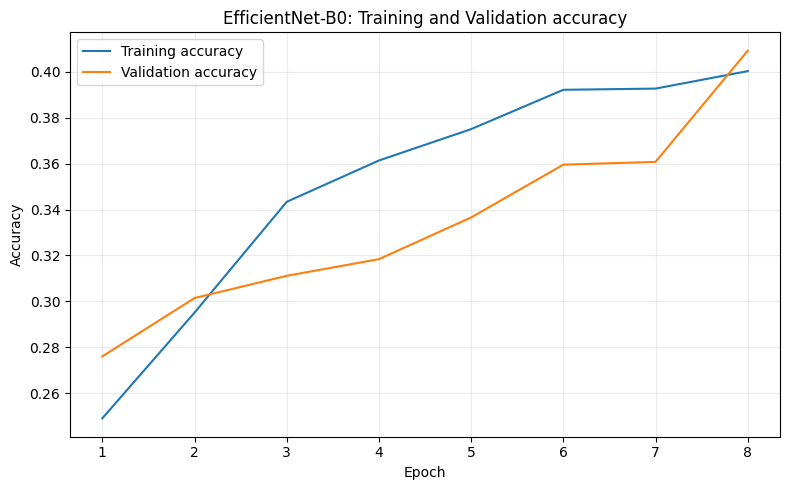

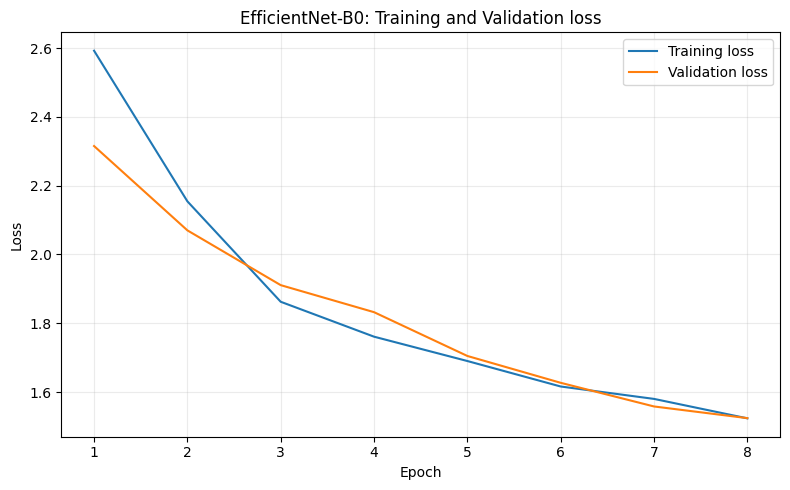

{}

In [24]:
history_efficientnet_b0 = []
best_val_loss = float("inf")
# Stops model after 4 epochs of not improving validation loss
early_stop_rate = 4
epochs_without_improvement = 0
# Reduce learning rates when validation loss stagnates
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

for epoch in range(1, NUM_EPOCHS_STAGE1 + 1):
    train_stats = run_epoch(
        efficientnet_b0, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE1
    )

    val_stats = run_epoch(
        efficientnet_b0, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE1
    )

    history_efficientnet_b0.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS_STAGE1}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

    scheduler.step(val_stats['loss'])

    # Stop training if validation loss does not improve
    if val_stats['loss'] < best_val_loss:
        best_val_loss = val_stats['loss']
        epochs_without_improvement = 0
        # Save best model
        torch.save(efficientnet_b0.state_dict(), "best_efficientnet_b0_stage1.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_rate:
        print("Early stopping triggered!")
        break

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_efficientnet_b0,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="EfficientNet-B0",
    show_plots = True,
    save_plots = False
)

#### 2.3.2 Fine-Tuning the Last EfficientNet Blocks
After training the classification head, the best Stage 1 checkpoint is restored.

For the second stage, the following parts of EfficientNet-B0 are unfrozen:

- The final block group (blocks[-1])
- The final convolutional head (conv_head)
- The classification layer (classifier)

All earlier layers remain frozen.

A smaller learning rate is applied to the pretrained layers than to the classification head to reduce the risk of making unnecessarily large changes to the learned features.

The model is trained for a maximum of 20 epochs.

Early stopping is applied with a patience of seven epochs. Additionally, the learning rate is reduced when validation loss stops improving.

As with ResNet18, the checkpoint with the lowest validation loss is saved for further evaluation.

In [40]:
# Restore best model from Stage 1
efficientnet_b0.load_state_dict(
    torch.load(
        "best_efficientnet_b0_stage1.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

# Freeze all layers
for param in efficientnet_b0.parameters():
    param.requires_grad = False

# Unfreeze final block group
for param in efficientnet_b0.blocks[-1].parameters():
    param.requires_grad = True

# Unfreeze final convolutional head
for param in efficientnet_b0.conv_head.parameters():
    param.requires_grad = True

# Unfreeze classifier
for param in efficientnet_b0.classifier.parameters():
    param.requires_grad = True

# Different learning rates
optimizer = torch.optim.AdamW(
    [
        {
            "params": efficientnet_b0.blocks[-1].parameters(),
            "lr": 1e-4
        },
        {
            "params": efficientnet_b0.conv_head.parameters(),
            "lr": 1e-4
        },
        {
            "params": efficientnet_b0.classifier.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)

# New scheduler for Stage 2
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

Epoch [1/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 1.4052 | Train Acc: 45.14% | Val Loss: 1.5271 | Val Acc: 41.40%


Epoch [2/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [2/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

...

Epoch [17/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [17/20] | Train Loss: 0.6080 | Train Acc: 75.08% | Val Loss: 1.1441 | Val Acc: 51.21%


Epoch [18/20] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [18/20] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [18/20] | Train Loss: 0.5978 | Train Acc: 75.58% | Val Loss: 1.1374 | Val Acc: 51.33%
Early stopping triggered!


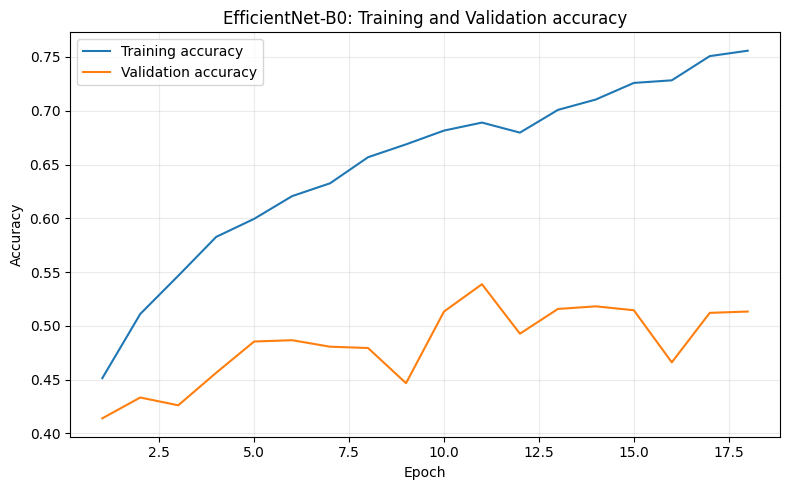

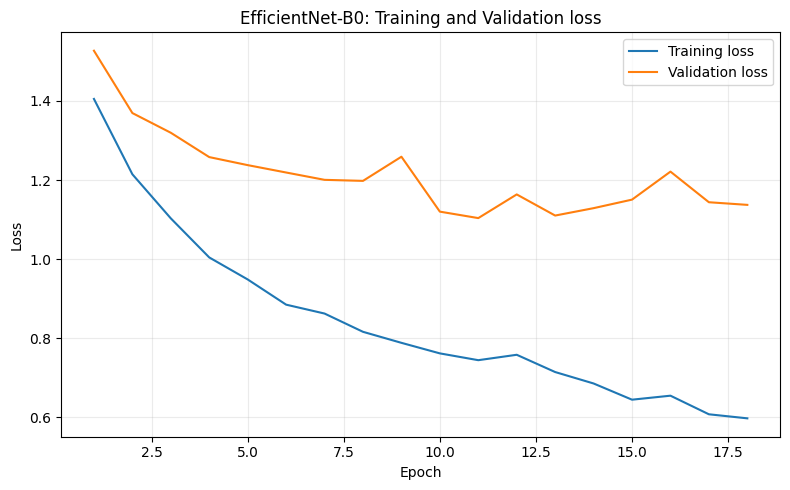

{}

In [41]:
history_efficientnet_b0 = []
best_val_loss = float("inf")
# Stops model after 4 epochs of not improving validation loss
early_stop_rate = 7
epochs_without_improvement = 0
# Reduce learning rates when validation loss stagnates
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=4
)

for epoch in range(1, NUM_EPOCHS_STAGE2 + 1):
    train_stats = run_epoch(
        efficientnet_b0, loaders['train'], optimizer,
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE2
    )

    val_stats = run_epoch(
        efficientnet_b0, loaders['val'],
        epoch=epoch, num_epochs=NUM_EPOCHS_STAGE2
    )

    history_efficientnet_b0.append({
      'epoch': epoch,
      'train_loss': train_stats['loss'],
      'train_accuracy': train_stats['accuracy'],
      'val_loss': val_stats['loss'],
      'val_accuracy': val_stats['accuracy']
    })

    tqdm.write(
      f"Epoch [{epoch}/{NUM_EPOCHS_STAGE2}] | "
      f"Train Loss: {train_stats['loss']:.4f} | "
      f"Train Acc: {train_stats['accuracy']:.2%} | "
      f"Val Loss: {val_stats['loss']:.4f} | "
      f"Val Acc: {val_stats['accuracy']:.2%}"
    )

    scheduler.step(val_stats['loss'])

    # Stop training if validation loss does not improve
    if val_stats['loss'] < best_val_loss:
        best_val_loss = val_stats['loss']
        epochs_without_improvement = 0
        # Save best model
        torch.save(efficientnet_b0.state_dict(), "best_efficientnet_b0_stage2.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= early_stop_rate:
        print("Early stopping triggered!")
        break

# Plot training metrics over epochs
from src.metrics import plot_training_history
plot_training_history(
    history_efficientnet_b0,
    output_dir=OUTPUT_DIR / "metrics",
    model_name="EfficientNet-B0",
    show_plots = True,
    save_plots = False
)

**Stage 2 Observations**

Fine-tuning substantially improves the training performance of EfficientNet-B0.

Training accuracy increases from approximately 45% in the first epoch to 75% in the final epoch. At the same time, training loss decreases from approximately 1.40 to 0.6.

Validation accuracy also improves, reaching approximately 54% in epoch 11.

However, validation loss decreases more slowly than training loss and fluctuates during the later epochs. This indicates a growing difference between training and validation performance, suggesting that the model may be starting to overfit.

The fine-tuning stage nevertheless achieves substantially better validation accuracy than the initial classifier-only training stage.

These results suggest that adapting the deeper layers of EfficientNet-B0 is beneficial for the knee X-ray classification task, although further improvements in generalization remain necessary.

#### 2.3.3 Evaluation of EfficientNet-B0

In [42]:
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    actual, probs = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        actual.append(y.numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(actual), np.concatenate(probs)

def summarize_metrics(y_true, probabilities, class_names):
    predictions = probabilities.argmax(axis=1)
    results = {'accuracy': accuracy_score(y_true, predictions)}
    present = np.unique(y_true)
    if len(class_names) == 2 and len(present) == 2:
        results['auroc'] = roc_auc_score(y_true, probabilities[:, 1])
    elif len(present) == len(class_names):
        results['auroc'] = roc_auc_score(
            y_true, probabilities, labels=np.arange(len(class_names)),
            multi_class='ovr', average='macro')
    else:
        results['auroc'] = float('nan')
        print('AUROC undefined: not all classes appear in this validation split.')
    return results, confusion_matrix(y_true, predictions,
                                      labels=np.arange(len(class_names)))

# Load best model
efficientnet_b0.load_state_dict(
    torch.load(
        # Newly trained models appear in the root folder
        #"best_efficientnet_b0_stage2.pth",
        # While the best models are in folder /models
        "./models/best_efficientnet_b0_stage2.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

y_val, val_prob = get_predictions(efficientnet_b0, loaders['val'])
class_names = train_source.classes
metrics, cm = summarize_metrics(y_val, val_prob, class_names)
print('Validation metrics:', metrics)
print('Confusion matrix (rows=true, cols=predicted):')
display(pd.DataFrame(cm, index=class_names, columns=class_names))

Validation metrics: {'accuracy': 0.5387409200968523, 'auroc': np.float64(0.8167864655859661)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,198,64,59,5,2
1,64,54,30,5,0
2,42,36,115,18,1
3,7,6,31,54,8
4,0,0,1,2,24


Current backend: module://matplotlib_inline.backend_inline
True labels: (1656,)
Predicted probabilities: (1656, 5)


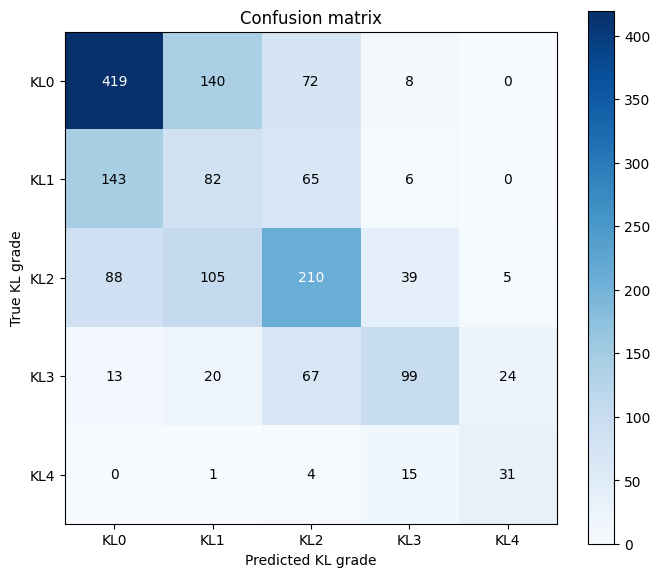

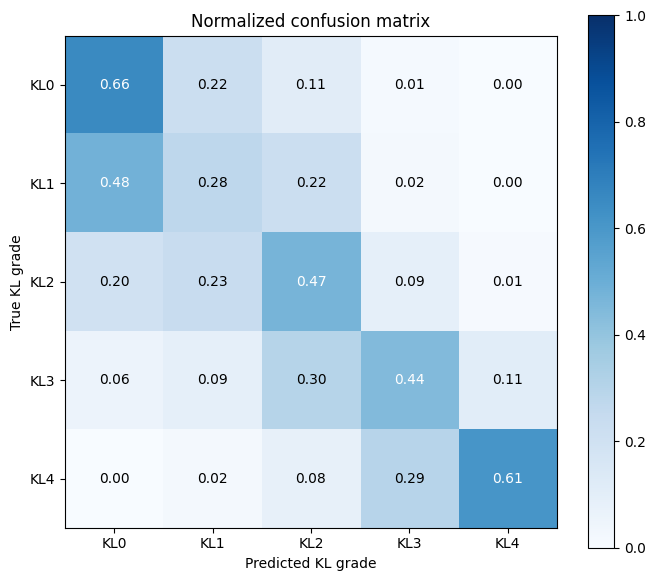

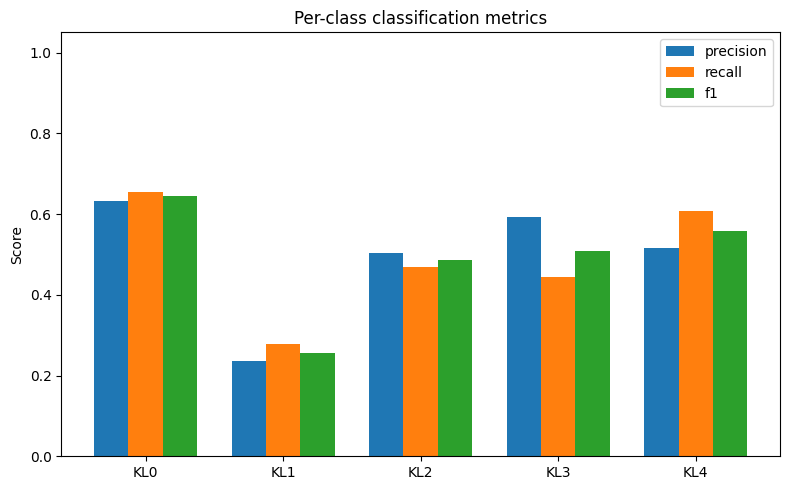

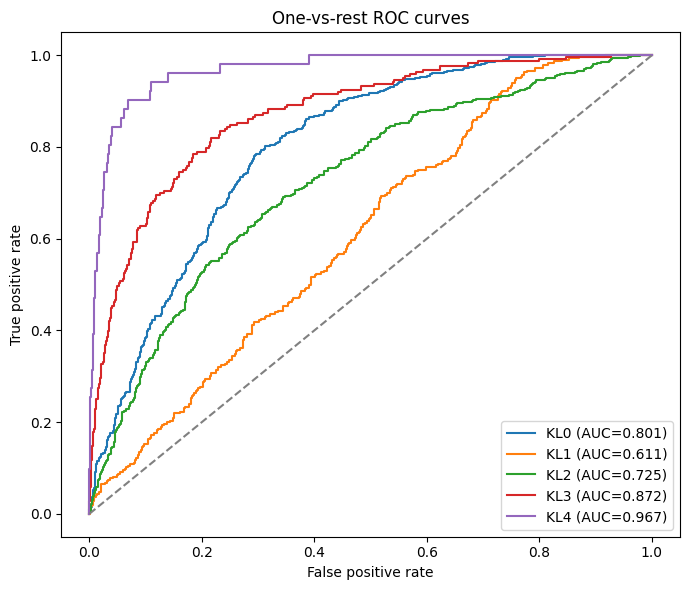

{'model_name': 'Efficientnet-B0', 'n_samples': 1656, 'accuracy': 0.5078502415458938, 'balanced_accuracy': 0.49086541208382084, 'macro_f1': 0.49001671526085994, 'weighted_f1': 0.5105058654668158, 'quadratic_weighted_kappa': 0.6569269739946814, 'mae': 0.6364734299516909, 'macro_auroc_ovr': 0.7953317454711557}


In [43]:
import matplotlib
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")

print("Current backend:", matplotlib.get_backend())

# Generate predictions
y_test, test_prob = get_predictions(efficientnet_b0, loaders["test"])

print("True labels:", y_test.shape)
print("Predicted probabilities:", test_prob.shape)

from src.metrics import evaluate_predictions

# Evaluate CNN performance
results = evaluate_predictions(
    y_true=y_test,
    y_prob=test_prob,
    model_name="Efficientnet-B0",
    show_plots=True,
    save_plots=False
)

print(results)

#### 2.3.3 EfficientNet-B0 Results

The fine-tuned EfficientNet-B0 model achieves a validation accuracy of approximately **52.1%** and a macro-averaged AUROC of **0.818**.

Although these validation results are comparable to those of ResNet18, the performance on the test dataset is noticeably lower.

The test accuracy decreases to approximately **38.2%**, while the macro F1-score reaches **0.364** and quadratic weighted kappa reaches **0.542**. The test AUROC is approximately **0.729**.

This difference suggests that EfficientNet-B0 does not generalize as consistently to the test dataset in the evaluated configuration.

The training history also shows a substantial difference between training and validation accuracy during the later epochs, indicating possible overfitting.

Therefore, although EfficientNet-B0 demonstrates an ability to learn features relevant to osteoarthritis severity, the current fine-tuning configuration does not achieve the same test performance as ResNet18.

Further investigation of learning rates, regularization, checkpoint selection, and possible differences between the validation and test distributions could help explain these results.

## 3. Comparison of ResNet18 and EfficientNet-B0

Both pretrained models were trained using a two-stage transfer learning approach. In the first stage, only the classification head was trained. In the second stage, selected deeper layers were unfrozen and fine-tuned.

The same dataset splits, class definitions, batch size, and general evaluation procedure were used for both architectures.

The final comparison is based on the test dataset containing 1'656 images.

| Metric                     | ResNet-18   | Efficientnet-B0 |
|----------------------------|-------------|-----------------|
| accuracy                   | 53.99%      | 50.79%          |
| balanced_accuracy          | 53.70%      | 49.09%          |
| macro_f1                   | 0.5233      | 0.4900          |
| weighted_f1                | 0.5230      | 0.5105          |
| quadratic_weighted_kappa   | 0.6684      | 0.6569          |
| mae                        | 0.6262      | 0.6365          |
| macro_auroc_ovr            | 0.8064      | 0.7953          |


ResNet18 achieves better performance than EfficientNet-B0 across all evaluated metrics.

The difference is most noticeable in classification accuracy, with ResNet18 correctly predicting approximately 54.0% of the KL grades compared with 50.8% for EfficientNet-B0.

ResNet18 also achieves higher balanced accuracy and macro F1-score. This suggests that it performs somewhat better across the five severity classes, even when accounting for class imbalance.

However, both models demonstrate limitations in predicting the exact KL grade, as approximately half of the test images are incorrectly classified.

Since Kellgren-Lawrence grades represent ordered categories, quadratic weighted kappa and mean absolute error are particularly useful for evaluating the magnitude of classification errors.

ResNet18 achieves a slightly higher quadratic weighted kappa of 0.668 compared with 0.657 for EfficientNet-B0. Similarly, its lower mean absolute error of 0.626 compared with 0.636 indicates slightly smaller absolute differences between predicted and actual severity grades.

The difference in macro-averaged AUROC is also relatively small. ResNet18 achieves an AUROC of 0.806, while EfficientNet-B0 achieves 0.795. Both models therefore demonstrate similar discriminative ability across the five KL grades.

Overall, ResNet18 achieves the better results under the investigated training configurations, particularly for exact classification accuracy and macro F1-score.

Nevertheless, the differences between the architectures are relatively small for several metrics. Without additional statistical analysis, it cannot be concluded that these differences are statistically significant.

These findings suggest that the comparatively simple ResNet18 architecture is an effective choice for the investigated knee osteoarthritis classification task, as the more complex EfficientNet-B0 architecture did not provide a performance advantage under the tested conditions.
